# make daily profiles of aircraft measurements
* don't segregate any values out
* do segregate out thermal  downdraft measurements? - LWC / updraft values

In [156]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FixedLocator, NullFormatter
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util
from glob import glob
import seaborn as sns
import imageio 
import tempfile
import pandas as pd
from metpy.calc import wind_direction, wind_speed
from metpy.units import units
from scipy.stats import binned_statistic
from functools import reduce


sys.path.append('/home/users/esree/dcmex_instruments/faam_data/')
# loads of homemade functions <3 <3
from faam_data_functions import faam_mo_files, time_adjust, get_nc_variable, mask_data, flatten_20hz_variable, mo_mean, datetime_to_sec, cloud_pass_time
from faam_data_functions_v2 import faam_mo_files_v2, make_cdp_psd_v2, make_cdp_conc, cloud_pass_time_v2

sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz, ztp, drag


In [2]:
faam_mo_paths_dic = faam_mo_files_v2() # dictionary containing dates + paths to nc files
date = '220730'
date_dict = faam_mo_paths_dic[date]
core_phys_pth = date_dict['cloud_physics_1hz']
faam_pth = date_dict['faam_core']
faam_pth_high = date_dict['faam_core_high']
mo_path = date_dict['mo_non_core_1hz']
mo_path_64hz = date_dict['mo_non_core']

In [189]:
### cloud droplet concentration #######################################
new_cdp_high_rate = make_cdp_conc(date_dict, file_name = 'cloud_physics') # this has no averaging
new_cdp_1hz = make_cdp_conc(date_dict, file_name = 'cloud_physics_1hz')

## faam alt + temp + tas + w - this is default 1hz, cba to change to higher one
alt_unit, alt_longname, alt = get_nc_variable(faam_pth_high, 'ALT_GIN')
alt_flat, alt_time_high = flatten_20hz_variable(alt)
temp_unit, temp_longname, temp = get_nc_variable(faam_pth_high, 'TAT_DI_R')
temp_c = temp - 273.15
temp_c = temp_c.rename({'Time': 'time'})
temp_c_unit ='C'

pressure_unit, pressure_longname, pressure = get_nc_variable(faam_pth_high, 'P10_STAT')
pressure = pressure.rename({'Time': 'time'})
pressure_flat, pressure_time_high = flatten_20hz_variable(pressure)

# other wind components
faam_u_unit, faam_u_longname, faam_u = get_nc_variable(faam_pth_high, 'U_C')
faam_u = faam_u.rename({'Time': 'time'})
u_flat, u_time_high = flatten_20hz_variable(faam_u)
u = u_flat.compute() * units('m/s')
faam_v_unit, faam_v_longname, faam_v = get_nc_variable(faam_pth_high, 'V_C')
faam_v = faam_v.rename({'Time': 'time'})
v_flat, v_time_high = flatten_20hz_variable(faam_v)
v = v_flat.compute() * units('m/s')
uv_wind_direction = wind_direction(u, v, convention="from") # where wind coming from
uv_wind_speed = wind_speed(u, v)

faam_w_unit_high, faam_w_longname_high, faam_w_high = get_nc_variable(faam_pth_high, 'W_C')
faam_w_high = faam_w_high.rename({'Time': 'time'})
w_high_flat, w_time_high = flatten_20hz_variable(faam_w_high)

tas_unit_high, tas_longname_high, tas_high = get_nc_variable(faam_pth_high, 'TAS_RVSM')
tas_high = tas_high.rename({'Time': 'time'})
tas_flat, tas_time_high = flatten_20hz_variable(tas_high)
LWC_unit_64hz, LWC_longname_64hz, LWC_64hz = mo_mean(mo_path_64hz, ('LWC1','LWC2'))


combined_dic = {
    'pressure': {'data': pressure_flat, 'unit': pressure_unit, 'time': pressure_time_high, 'colour': 'black', 'label' : 'Pressure'},
    'w_faam_high': {'data': w_high_flat, 'unit': faam_w_unit_high, 'time': w_time_high, 'colour': 'coral', 'label' : 'W faam 32hz'},
    'uv_wind_direction': {'data': uv_wind_direction, 'unit': uv_wind_direction.data.units, 'time': uv_wind_direction['time'].values, 'colour': 'seagreen', 'label' : 'UV Direction'},
    'uv_wind_speed': {'data': uv_wind_speed, 'unit': uv_wind_speed.data.units, 'time': uv_wind_speed['time'].values, 'colour': 'navy', 'label' : 'UV Speed'},
    'N_d_high': {'data': new_cdp_high_rate, 'unit': new_cdp_high_rate.attrs.get('units'), 'time': new_cdp_high_rate['time'].values, 'colour': 'gray', 'label' : 'N_d high rate'},
    'alt_gin': {'data': alt_flat, 'unit': alt_unit, 'time': alt_time_high, 'colour': 'tab:red', 'label' : 'Alt'},
    'temp': {'data': temp_c, 'unit': temp_c_unit, 'time': temp_c['time'].values, 'colour': 'tab:purple', 'label' : 'Temp'},
    'mean_LWC_64hz': {'data': LWC_64hz, 'unit': LWC_unit_64hz, 'time': LWC_64hz['Time'].values, 'colour': 'purple', 'label' : 'LWC 64hz'},
    'tas_high': {'data': tas_flat, 'unit': tas_unit_high, 'time': tas_time_high, 'colour': 'darkorange', 'label' : 'TAS 32hz'}}

/home/users/esree/dcmex_instruments/faam_data/faam_data_functions_v2.py:248: FutureWarning: updating coordinate 'time_highres', which is a PandasMultiIndex, would leave the multi-index level coordinates ['time', 'sps25'] in an inconsistent state. This will raise an error in the future. Use `.drop_vars(['time_highres', 'time', 'sps25'])` to drop the coordinates' values before assigning new coordinate values.
  stacked = stacked.assign_coords(time_highres=new_time) # new highres UTC time


## how does this relate to model values?

In [40]:
namelist_path = '/home/users/esree/simple-graupel-model/v4_1_experiments/'
name_of_namelist = 'namelist_v4_1_30th_1.txt'

with open(namelist_path + name_of_namelist, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

In [56]:
zbase = ptz(namelist['pbase']) # height of cloud base (m)
#namelist['pbase']
zbase

3511.511330803221

## vertical velocity

In [46]:
altitude_values = combined_dic['alt_gin']['data']#.values
vertical_velocity_values = combined_dic['w_faam_high']['data']#.values
pressure_values = combined_dic['pressure']['data']#.values

# would like to use lwc as a mask, but on different time - need to interpolate
lwc_values = combined_dic['mean_LWC_64hz']['data']#.values
lwc_values = lwc_values.rename({'Time': 'time'})
lwc_aligned = lwc_values.interp(time=vertical_velocity_values['time'])

## make a mask
specific LWC / updraft thresholds

### one go at a time

In [112]:
# mask out vertical velocity values where lwc is less than 0.25 g/m3

lwc_mask = lwc_aligned > 0.25 # lwc greater than 0.25 g/m3
lwc_mask = lwc_mask.compute() # convert to numpy array for masking

vv_mask = vertical_velocity_values > 0 
vv_mask = vv_mask.compute() # convert to numpy array for masking

mask = lwc_mask & vv_mask # combine masks

masked_vertical_velocity = vertical_velocity_values.where(mask, drop=True).compute()
masked_altitude = altitude_values.where(mask, drop=True).compute()
masked_pressure = pressure_values.where(mask, drop=True).compute()

(670.0, 400.0)

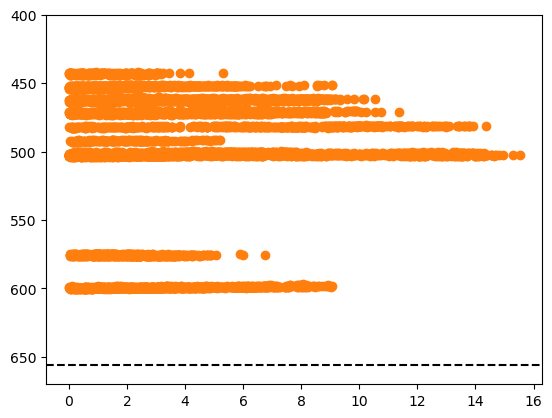

In [113]:
# do as altitude
plt.scatter(masked_vertical_velocity, masked_altitude)
plt.axhline(y=zbase, color='black', linestyle='--', label='cloud_base')


# do as pressure
plt.scatter(masked_vertical_velocity, masked_pressure)
plt.axhline(y=namelist['pbase'], color='black', linestyle='--', label='cloud_base')
plt.ylim(670, 400)

In [ ]:
w, alt, p = xr.align(masked_vertical_velocity, masked_altitude, masked_pressure, join='inner')

# explicit names, so the bin dims are always 'alt_bins' and 'pressure_bins'
alt = alt.rename('alt')
p   = p.rename('pressure')

# --- altitude: 100 m linear bins ---
alt_bins = np.arange(0, np.nanmax(alt.values) + 100, 100)
w_by_alt = w.groupby_bins(alt, bins=alt_bins)

# --- pressure: 30 bins, uniform in ln(p) ---
p_min, p_max = np.nanmin(p.values), np.nanmax(p.values)
p_bins = np.geomspace(p_min, p_max, 31)
w_by_p = w.groupby_bins(p, bins=p_bins)

# statistics
alt_mean, alt_std, alt_n = w_by_alt.mean(), w_by_alt.std(), w_by_alt.count()
p_mean,   p_std,   p_n   = w_by_p.mean(),   w_by_p.std(),   w_by_p.count()

# bin centres (arithmetic for altitude, geometric for pressure)
alt_centres = np.array([iv.mid for iv in alt_mean['alt_bins'].values])
p_centres   = np.array([np.sqrt(iv.left * iv.right) for iv in p_mean['pressure_bins'].values])

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_3681862/2548144002.py:4: SyntaxWarning: invalid escape sequence '\p'
  ax.fill_betweenx(p_centres, p_mean - 2 * p_std, p_mean + 2 * p_std, alpha=0.3, label='$\pm 2\sigma$')


(0.0, 12.0)

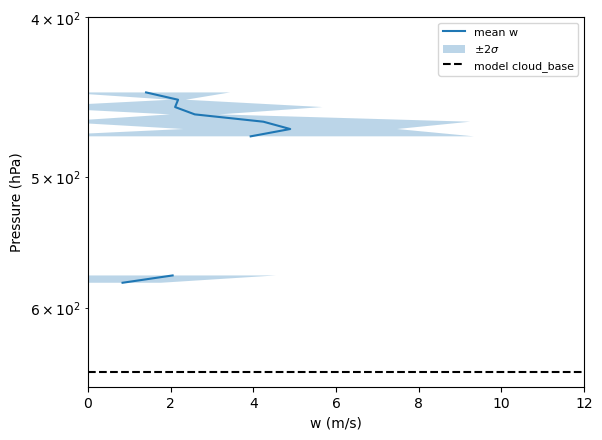

In [115]:
#plt.plot(p_mean, p_centres)
fig, ax = plt.subplots()
ax.plot(p_mean, p_centres, label='mean w')
ax.fill_betweenx(p_centres, p_mean - 2 * p_std, p_mean + 2 * p_std, alpha=0.3, label='$\pm 2\sigma$')

ax.set_yscale('log')
ax.invert_yaxis() 
ax.set_ylabel('Pressure (hPa)')
ax.set_xlabel('w (m/s)')
ax.axhline(y=namelist['pbase'], color='black', linestyle='--', label='model cloud_base')
ax.legend(fontsize=8)
ax.set_ylim(670, 400)
ax.set_xlim(0, 12)

<>:7: SyntaxWarning: invalid escape sequence '\p'
<>:7: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_3681862/1792645863.py:7: SyntaxWarning: invalid escape sequence '\p'
  alpha=0.3, label='$\pm 2\sigma$', color='red')


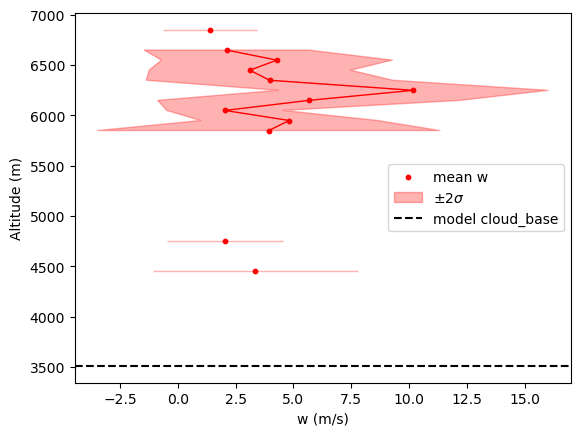

In [111]:
fig, ax = plt.subplots()
ax.plot(alt_mean, alt_centres, color='red', linewidth=1, zorder=1)
ax.scatter(alt_mean, alt_centres, color='red', s=10, marker='o', label='mean w', zorder=2)
ax.fill_betweenx(alt_centres,
                 alt_mean - 2 * alt_std,
                 alt_mean + 2 * alt_std,
                 alpha=0.3, label='$\pm 2\sigma$', color='red')

ax.set_ylabel('Altitude (m)')
ax.set_xlabel('w (m/s)')
ax.axhline(y=zbase, color='black', linestyle='--', label='model cloud_base')
ax.legend()

### multi-plot, for different thresholds

In [ ]:
# options:
## vertical velocity (vv): no minimum (none), >0, >1
## lwc: no minimum (none), >0.25

# combinations: vv none + lwc none, ## no limits - all data
#               vv none + lwc >0.25, ## in cloud, all vertical velocity
#               vv >0 + lwc >0.25, ## positive vertical velocity in cloud
#               vv >1 + lwc >0.25 ## in cloud, slightly stronger vertical velocity

# mask combinations
mask_combinations = {
    'vv_none_lwc_none': (None, None),
    'vv_none_lwc_0.25': (None, 0.25),
    'vv_0_lwc_0.25': (0, 0.25),
    'vv_1_lwc_0.25': (1, 0.25)}

## function to pull out data - will use same set of bins throughout -> from unmasked data
# alt bins
alt_bins = np.arange(0, np.nanmax(altitude_values.values) + 100, 100)
# pressure bins
p_min, p_max = np.nanmin(pressure_values.values), np.nanmax(pressure_values.values)
p_bins = np.geomspace(p_min, p_max, 31)

# not using SD, but quantiles instead - so can see if distribution is skewed
def mask_and_stats(combined_dict_f, mask_combo, p_bins_f, alt_bins_f, q=(0.025, 0.975)):
    """
    function to apply mask to data and calculate mean and std for each mask combination, for both altitude and pressure bins
    """
    vv_min, lwc_min = mask_combo
    q_lo, q_hi = q
    
    alt_all = combined_dict_f['alt_gin']['data']
    w_all   = combined_dict_f['w_faam_high']['data']
    p_all   = combined_dict_f['pressure']['data']

    lwc = combined_dict_f['mean_LWC_64hz']['data'].rename({'Time': 'time'})
    lwc = lwc.interp(time=w_all['time'])

    masks = []
    if vv_min is not None:
        masks.append(w_all > vv_min)
    if lwc_min is not None:
        masks.append(lwc > lwc_min)

    if masks:
        mask = reduce(np.logical_and, masks).compute()   # compute once, reuse
    else:
        mask = xr.ones_like(w_all, dtype=bool).compute()

    w   = w_all.where(mask, drop=True).compute()
    alt = alt_all.where(mask, drop=True).compute()
    p   = p_all.where(mask, drop=True).compute()

    w, alt, p = xr.align(w, alt, p, join='inner')

    if w.size == 0:
        return None

    out = {}
    for name, var, bins in (('alt', alt, alt_bins_f), ('p', p, p_bins_f)):
        grouped = w.groupby_bins(var.rename(name), bins=bins, include_lowest=True)
        quant = grouped.quantile([q_lo, 0.5, q_hi])      # dims: (<name>_bins, quantile)
        out[f'{name}_mean'] = grouped.mean()
        out[f'{name}_n']    = grouped.count()
        out[f'{name}_lo']   = quant.sel(quantile=q_lo)
        out[f'{name}_med']  = quant.sel(quantile=0.5)
        out[f'{name}_hi']   = quant.sel(quantile=q_hi)
    
    out['q'] = q
    return out



In [146]:
dic_results = {
        key: mask_and_stats(combined_dic, combo, p_bins, alt_bins)
        for key, combo in mask_combinations.items()
    }

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1598: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


In [147]:
dic_results.keys()

dict_keys(['vv_none_lwc_none', 'vv_none_lwc_0.25', 'vv_0_lwc_0.25', 'vv_1_lwc_0.25'])

In [153]:
def centres_from(da, geometric=False):
    intervals = da[da.dims[0]].values
    if geometric:
        return np.array([np.sqrt(iv.left * iv.right) for iv in intervals])
    return np.array([iv.mid for iv in intervals])

def plot_profile(ax, data, prefix, geometric, color, min_count=0):
    y    = centres_from(data[f'{prefix}_mean'], geometric=geometric)
    ok   = data[f'{prefix}_n'].values >= min_count
    mean = data[f'{prefix}_mean'].values
    med  = data[f'{prefix}_med'].values
    lo   = data[f'{prefix}_lo'].values
    hi   = data[f'{prefix}_hi'].values

    q_lo, q_hi = data['q']
    ax.plot(med[ok], y[ok], color=color, label='median w')
    ax.plot(mean[ok], y[ok], color=color, linestyle=':', label='mean w')
    ax.fill_betweenx(y[ok], lo[ok], hi[ok], color=color, alpha=0.3,
                     label=f'{q_lo*100:g}-{q_hi*100:g}th percentile')

Text(0.5, 0.98, 'vertical velocity profiles on 220730')

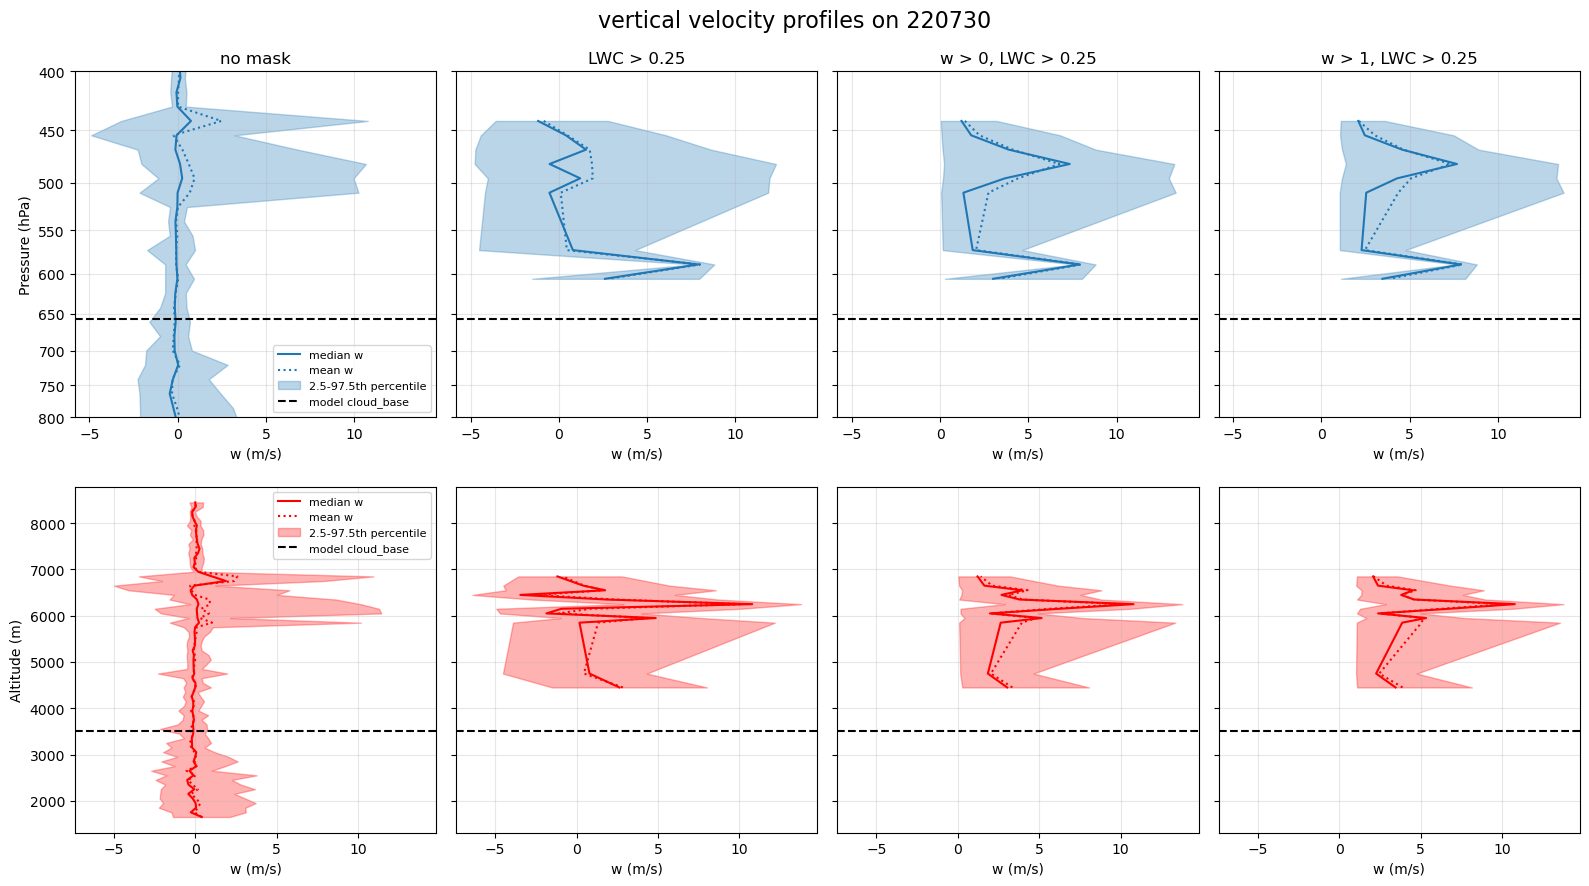

In [173]:
titles = {
    'vv_none_lwc_none': 'no mask',
    'vv_none_lwc_0.25': 'LWC > 0.25',
    'vv_0_lwc_0.25':    'w > 0, LWC > 0.25',
    'vv_1_lwc_0.25':    'w > 1, LWC > 0.25',
}

fig, axes = plt.subplots(2, 4, figsize=(16, 9), sharex='row', sharey='row')

for col, (key, title) in enumerate(titles.items()):
    data = dic_results[key]
    axes[0, col].set_title(title if data is not None else f'{title} (no data)')
    if data is None:
        continue
    plot_profile(axes[0, col], data, 'p',   geometric=True,  color='C0')
    plot_profile(axes[1, col], data, 'alt', geometric=False, color='red')
    axes[0, col].axhline(namelist['pbase'], color='black', linestyle='--', label='model cloud_base')
    axes[1, col].axhline(zbase, color='black', linestyle='--', label='model cloud_base')

# pressure row: log scale, plain tick labels, inverted (high pressure at the bottom)
for ax in axes[0]:
    ax.set_yscale('log')
    ax.yaxis.set_major_locator(FixedLocator([400, 450, 500, 550, 600, 650, 700, 750, 800]))
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
axes[0, 0].set_ylim(800, 400)          # larger value first = inverted; shared across the row
if not axes[0, 0].yaxis_inverted():    # safety net
    axes[0, 0].invert_yaxis()

# outer axis labels: y on the left column, x on every row
axes[0, 0].set_ylabel('Pressure (hPa)')
axes[1, 0].set_ylabel('Altitude (m)')
for ax in axes.flat:
    ax.set_xlabel('w (m/s)')
    ax.grid(alpha=0.3)
    ax.tick_params(labelbottom=True)   # x tick labels on both rows

# legends: one per row (colours differ between rows)
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)

# space between rows, then a separator line in the gap
fig.tight_layout(rect=[0, 0, 1, 0.95])   # leave the top 5% free for the suptitle
fig.subplots_adjust(hspace=0.2)   # was 0.35; try 0.15-0.25

fig.suptitle(f'vertical velocity profiles on {date}', fontsize=16, y=0.98)

## make the functions a bit more general - so can use for other variables

In [190]:
def get_var(d, spec, time_ref):
    """
    Fetch a variable and put it on the reference time axis.
    spec: a key in the dict, or a function taking the dict and returning a
          DataArray (for derived quantities such as wind speed).
    """
    da = spec(d) if callable(spec) else d[spec]['data']
    if 'Time' in da.dims:
        da = da.rename({'Time': 'time'})
    if not da['time'].equals(time_ref):
        da = da.interp(time=time_ref)
    return da


def build_mask(d, mask_combo, w_key='w_faam_high', lwc_key='mean_LWC_64hz'):
    """Boolean mask on the w time axis from the (vv_min, lwc_min) thresholds."""
    vv_min, lwc_min = mask_combo
    w_all = d[w_key]['data']

    masks = []
    if vv_min is not None:
        masks.append(w_all > vv_min)
    if lwc_min is not None:
        masks.append(get_var(d, lwc_key, w_all['time']) > lwc_min)

    mask = reduce(np.logical_and, masks) if masks else xr.ones_like(w_all, dtype=bool)
    return mask.compute()


def bin_stats(d, mask, var, p_bins_f, alt_bins_f, q=(0.025, 0.975),
              alt_key='alt_gin', p_key='pressure'):
    """Mean, median, lower/upper quantiles and counts of `var` in pressure and altitude bins."""
    q_lo, q_hi = q
    t = mask['time']

    x   = get_var(d, var,     t).where(mask, drop=True).compute()
    alt = get_var(d, alt_key, t).where(mask, drop=True).compute()
    p   = get_var(d, p_key,   t).where(mask, drop=True).compute()

    x, alt, p = xr.align(x, alt, p, join='inner')
    if x.size == 0:
        return None

    out = {}
    for name, coord, bins in (('alt', alt, alt_bins_f), ('p', p, p_bins_f)):
        grouped = x.groupby_bins(coord.rename(name), bins=bins, include_lowest=True)
        quant = grouped.quantile([q_lo, 0.5, q_hi])
        out[f'{name}_mean'] = grouped.mean()
        out[f'{name}_n']    = grouped.count()
        out[f'{name}_lo']   = quant.sel(quantile=q_lo)
        out[f'{name}_med']  = quant.sel(quantile=0.5)
        out[f'{name}_hi']   = quant.sel(quantile=q_hi)
    out['q'] = q
    return out

In [ ]:
masks = {key: build_mask(combined_dic, combo) for key, combo in mask_combinations.items()}

def run(var):
    return {key: bin_stats(combined_dic, m, var, p_bins, alt_bins) for key, m in masks.items()}

dic_results_w = run('w_faam_high')

# horizontal wind: a key in your dict...
dic_results_ws = run('uv_wind_speed')            # replace with your actual key
# ...or a derived quantity, e.g. from u and v components

dic_results_lwc = run('mean_LWC_64hz')            # replace with your actual key


/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1598: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1598: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


In [191]:

titles = {
    'vv_none_lwc_none': 'no mask',
    'vv_none_lwc_0.25': 'LWC > 0.25',
    'vv_0_lwc_0.25':    'w > 0, LWC > 0.25',
    'vv_1_lwc_0.25':    'w > 1, LWC > 0.25',
}

def centres_from(da, geometric=False):
    intervals = da[da.dims[0]].values
    if geometric:
        return np.array([np.sqrt(iv.left * iv.right) for iv in intervals])
    return np.array([iv.mid for iv in intervals])

def plot_profile(ax, data, prefix, geometric, color, var_label, min_count=0):
    y    = centres_from(data[f'{prefix}_mean'], geometric=geometric)
    ok   = data[f'{prefix}_n'].values >= min_count
    mean = data[f'{prefix}_mean'].values
    med  = data[f'{prefix}_med'].values
    lo   = data[f'{prefix}_lo'].values
    hi   = data[f'{prefix}_hi'].values

    q_lo, q_hi = data['q']
    ax.plot(med[ok], y[ok], color=color, label=f'median {var_label}')
    ax.plot(mean[ok], y[ok], color=color, linestyle=':', label=f'mean {var_label}')
    ax.fill_betweenx(y[ok], lo[ok], hi[ok], color=color, alpha=0.3,
                     label=f'{q_lo*100:g}-{q_hi*100:g}th percentile')

def plot_profiles(dic_results, var_label, xlabel, suptitle,
                  titles=titles, pbase=None, zbase=None,
                  p_ticks=(400, 450, 500, 550, 600, 650, 700, 750, 800),
                  p_ylim=(800, 400), min_count=0, xlim=None,
                  figsize=(16, 9), colors=('C0', 'red')):
    fig, axes = plt.subplots(2, len(titles), figsize=figsize,
                             sharex='row', sharey='row', squeeze=False)

    for col, (key, title) in enumerate(titles.items()):
        data = dic_results[key]
        axes[0, col].set_title(title if data is not None else f'{title} (no data)')
        if data is None:
            continue
        plot_profile(axes[0, col], data, 'p',   True,  colors[0], var_label, min_count)
        plot_profile(axes[1, col], data, 'alt', False, colors[1], var_label, min_count)
        if pbase is not None:
            axes[0, col].axhline(pbase, color='black', linestyle='--', label='model cloud_base')
        if zbase is not None:
            axes[1, col].axhline(zbase, color='black', linestyle='--', label='model cloud_base')

    # pressure row: log scale, plain tick labels, inverted
    for ax in axes[0]:
        ax.set_yscale('log')
        ax.yaxis.set_major_locator(FixedLocator(list(p_ticks)))
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
    axes[0, 0].set_ylim(*p_ylim)
    if not axes[0, 0].yaxis_inverted():
        axes[0, 0].invert_yaxis()

    if xlim is not None:
        axes[0, 0].set_xlim(*xlim)
        axes[1, 0].set_xlim(*xlim)

    axes[0, 0].set_ylabel('Pressure (hPa)')
    axes[1, 0].set_ylabel('Altitude (m)')
    for ax in axes.flat:
        ax.set_xlabel(xlabel)
        ax.grid(alpha=0.3)
        ax.tick_params(labelbottom=True)

    axes[0, 0].legend(fontsize=8)
    axes[1, 0].legend(fontsize=8)

    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.subplots_adjust(hspace=0.2)
    fig.suptitle(suptitle, fontsize=16, y=0.98)
    return fig, axes

### horizontal velocity

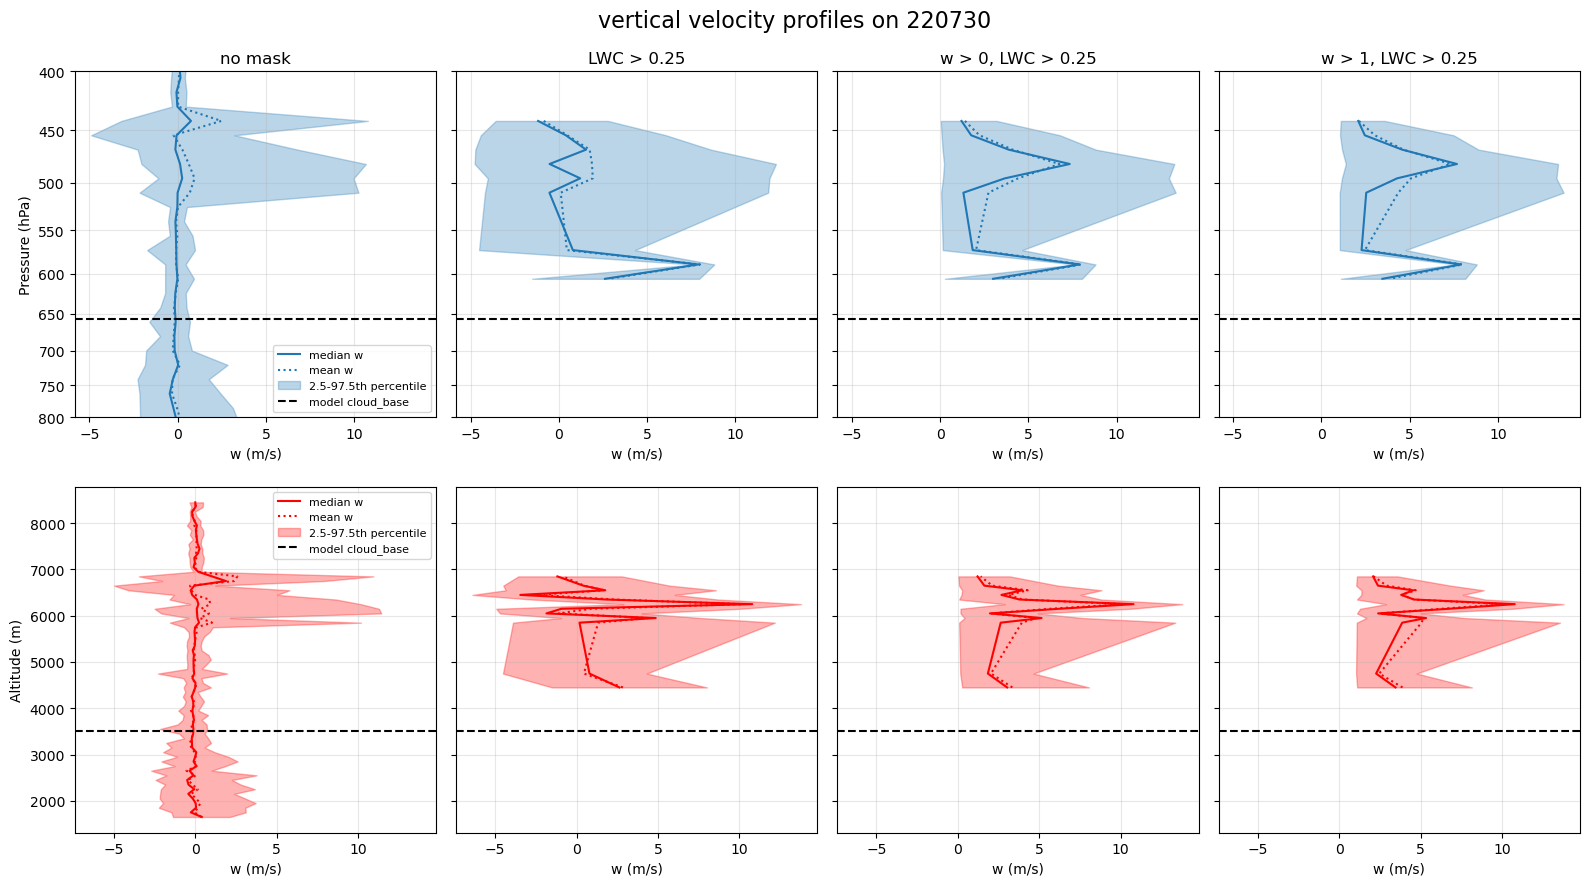

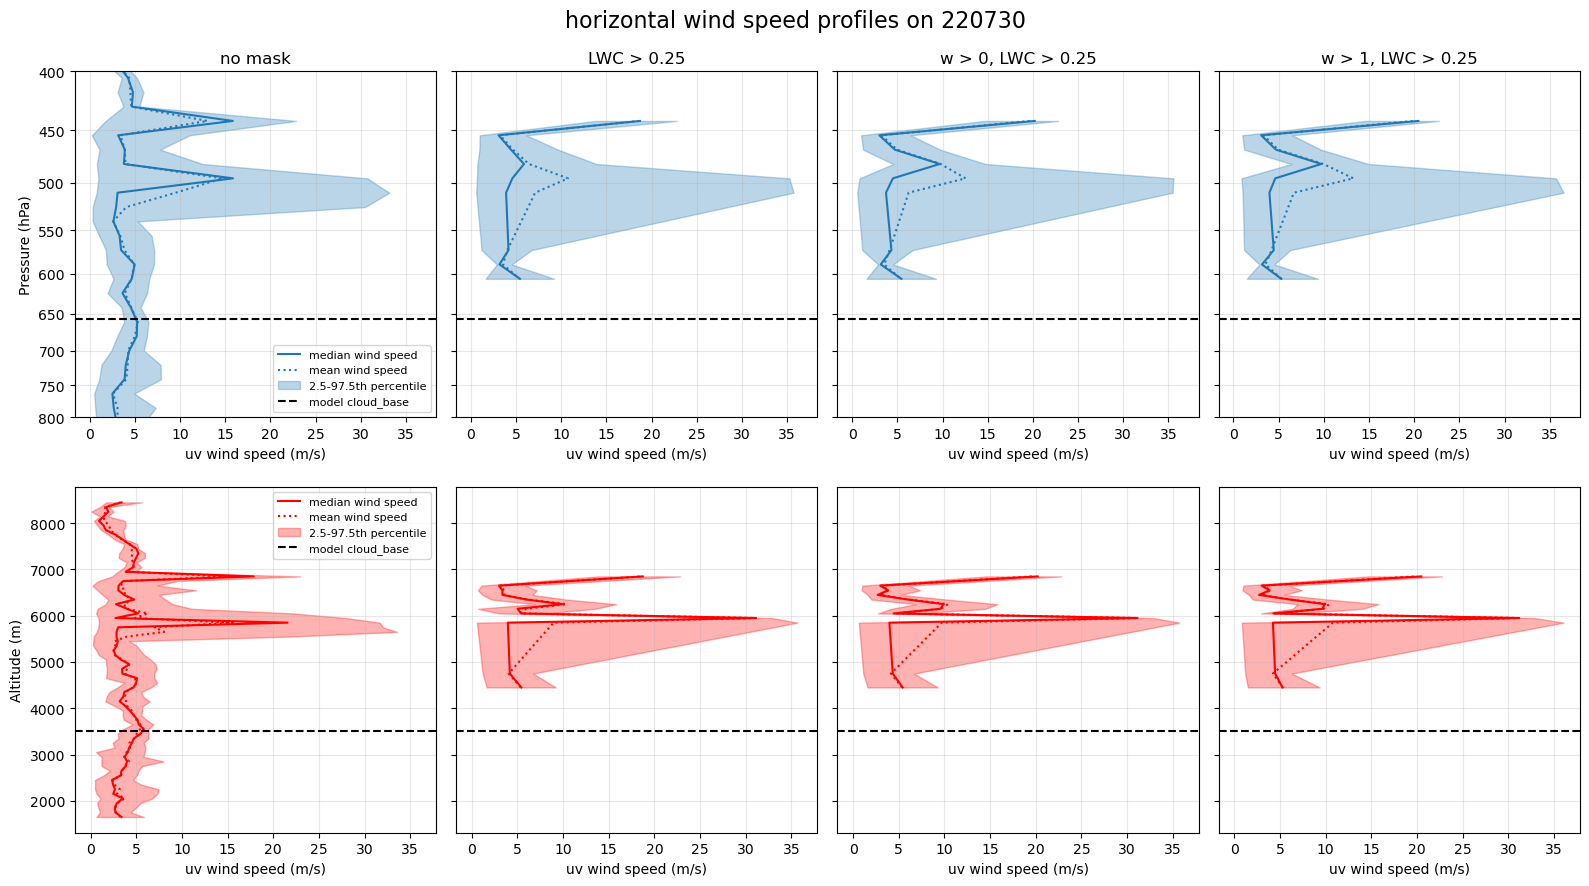

In [183]:
fig, axes = plot_profiles(dic_results_w, var_label='w', xlabel='w (m/s)',
                          suptitle=f'vertical velocity profiles on {date}',
                          pbase=namelist['pbase'], zbase=zbase)

fig, axes = plot_profiles(dic_results_ws, var_label='wind speed', xlabel='uv wind speed (m/s)',
                          suptitle=f'horizontal wind speed profiles on {date}',
                          pbase=namelist['pbase'], zbase=zbase)

### lwc

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1598: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


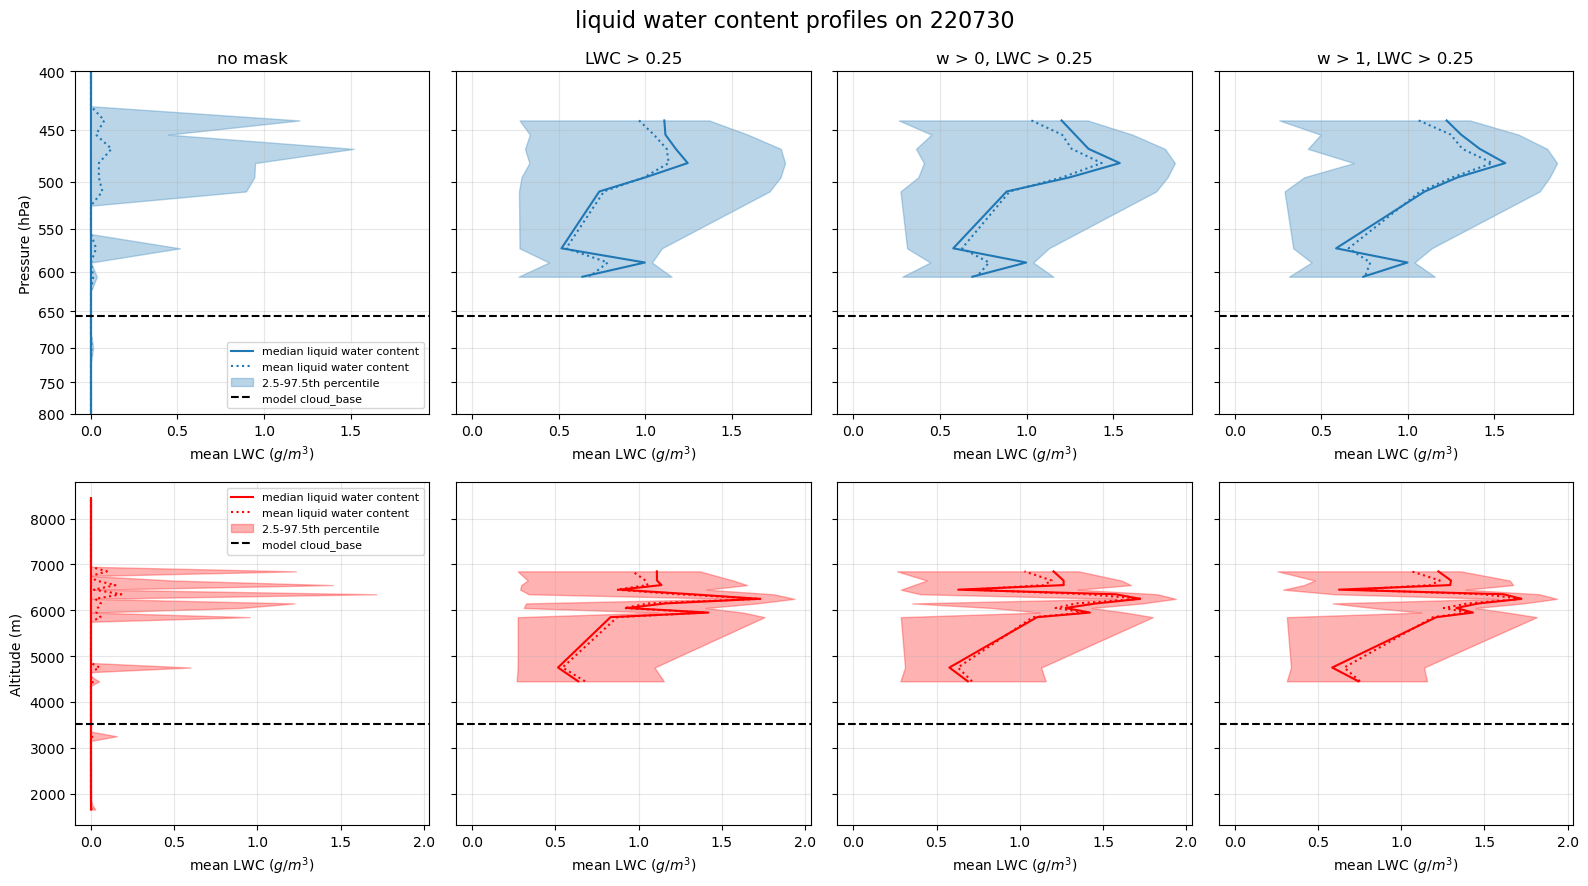

In [185]:
dic_results_lwc = run('mean_LWC_64hz')            # replace with your actual key

fig, axes = plot_profiles(dic_results_lwc, var_label='liquid water content', xlabel='mean LWC ($g/m^{3}$)',
                          suptitle=f'liquid water content profiles on {date}',
                          pbase=namelist['pbase'], zbase=zbase)

### temp
idk why it doesnt work - probably because different time

In [193]:
dic_results_temp = run('temp')            # replace with your actual key

KeyboardInterrupt: 

In [ ]:
fig, axes = plot_profiles(dic_results_temp, var_label='temperature', xlabel='mean temperature ($^{\circ}C$)',
                          suptitle=f'temperature profiles on {date}',
                          pbase=namelist['pbase'], zbase=zbase)